# Step 1 — Data Cleaning (explained)

This notebook is the **first step** of the ML project: make both CSV files trustworthy before any modeling.

## What we have
| File | Rows | About |
|------|------|-------|
| `music_data.csv` | ~5,000 | Streaming users (age, country, platform, listening habits…) |
| `world_happiness_data.csv` | ~1,500 | Country happiness scores by year (GDP, social support…) |

A natural later goal is to **merge them on `Country`** (e.g. “does happier countries listen differently?”). Cleaning must fix anything that would break that merge.

## What you need beyond “Python”
| Tool | Why |
|------|-----|
| **pandas** | Load / clean / join tables (the workhorse) |
| **numpy** | Numeric ops under the hood |
| **matplotlib** + **seaborn** | Plots to *see* problems (outliers, weird distributions) |
| **scikit-learn** | Later: train/test split, models, metrics (not needed yet) |
| **Jupyter** | Run cells, read explanations, experiment |

Already set up in this project: virtualenv `.venv` + `requirements.txt`.


## 0. Imports

We only need pandas/numpy/plotting for cleaning. scikit-learn comes later.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Nice defaults for plots
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

DATA = Path(".")
print("Working directory:", DATA.resolve())


Working directory: /home/wissemsirat/Documents/Projects/musicml


---
## 1. Load the music dataset

`pd.read_csv` reads a comma-separated file into a **DataFrame** (a table with named columns).


In [2]:
music = pd.read_csv(DATA / "music_data.csv")

print("Shape (rows, columns):", music.shape)
music.head()  # first 5 rows


Shape (rows, columns): (5000, 12)


,User_ID,Age,Country,Streaming Platform,Top Genre,Minutes Streamed Per Day,Number of Songs Liked,Most Played Artist,Subscription Type,Listening Time (Morning/Afternoon/Night),Discover Weekly Engagement (%),Repeat Song Rate (%)
0,U1000,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74
1,U1001,24,Germany,Deezer,Country,86,388,Ed Sheeran,Premium,Night,12.06,69.25
2,U1002,49,Germany,Deezer,Pop,363,368,Post Malone,Premium,Afternoon,47.19,67.38
3,U1003,55,Australia,YouTube,Reggae,348,349,Dua Lipa,Premium,Morning,31.27,76.51
4,U1004,13,Germany,Amazon Music,Reggae,30,328,Adele,Free,Night,30.68,43.41


### What each column means (music)
- **User_ID** — unique listener id (not a feature for ML; keep for tracking)
- **Age** — listener age
- **Country** — where the user is (join key with happiness)
- **Streaming Platform**, **Top Genre**, **Most Played Artist**, **Subscription Type**, **Listening Time** — categories
- **Minutes Streamed Per Day**, **Number of Songs Liked** — counts / amounts
- **Discover Weekly Engagement (%)**, **Repeat Song Rate (%)** — percentages (0–100 range expected)


In [3]:
# Column names + pandas dtypes (how Python currently stores each column)
music.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   User_ID                                   5000 non-null   str    
 1   Age                                       5000 non-null   int64  
 2   Country                                   5000 non-null   str    
 3   Streaming Platform                        5000 non-null   str    
 4   Top Genre                                 5000 non-null   str    
 5   Minutes Streamed Per Day                  5000 non-null   int64  
 6   Number of Songs Liked                     5000 non-null   int64  
 7   Most Played Artist                        5000 non-null   str    
 8   Subscription Type                         5000 non-null   str    
 9   Listening Time (Morning/Afternoon/Night)  5000 non-null   str    
 10  Discover Weekly Engagement (%)            5000 

In [4]:
# Quick numeric summary: min/max/mean help spot impossible values
music.describe()


,Age,Minutes Streamed Per Day,Number of Songs Liked,Discover Weekly Engagement (%),Repeat Song Rate (%)
count,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,36.664000,309.237200,253.51720,50.296464,42.391060
std,13.763844,172.029822,146.36928,23.171936,21.444121
min,13.000000,10.000000,1.00000,10.020000,5.000000
25%,25.000000,161.000000,126.00000,30.147500,24.195000
50%,37.000000,316.000000,254.00000,50.420000,41.960000
75%,49.000000,457.250000,382.00000,70.337500,60.740000
max,60.000000,600.000000,500.00000,89.990000,79.990000


In [5]:
# Categories: how many unique values, and a peek at the values
categorical_cols = [
    "Country",
    "Streaming Platform",
    "Top Genre",
    "Most Played Artist",
    "Subscription Type",
    "Listening Time (Morning/Afternoon/Night)",
]
for col in categorical_cols:
    print(f"\n{col} ({music[col].nunique()} unique):")
    print(music[col].value_counts())



Country (10 unique):
Country
Australia      526
South Korea    516
UK             516
Brazil         508
Canada         507
France         493
Japan          491
India          490
USA            482
Germany        471
Name: count, dtype: int64

Streaming Platform (6 unique):
Streaming Platform
Amazon Music    861
Tidal           850
Deezer          844
Spotify         827
YouTube         822
Apple Music     796
Name: count, dtype: int64

Top Genre (10 unique):
Top Genre
Reggae       532
Jazz         532
EDM          528
Rock         516
R&B          495
Metal        491
Hip-Hop      485
Country      484
Classical    475
Pop          462
Name: count, dtype: int64

Most Played Artist (10 unique):
Most Played Artist
Bad Bunny        528
Adele            519
Post Malone      519
Dua Lipa         502
Ed Sheeran       500
Taylor Swift     496
The Weeknd       490
BTS              488
Drake            481
Billie Eilish    477
Name: count, dtype: int64

Subscription Type (2 unique):
Subscrip

### Missing values & duplicates (music)

In ML, missing values and duplicate rows can quietly bias a model. Always check.


In [6]:
print("Missing values per column:")
print(music.isna().sum())

print("\nDuplicate rows:", music.duplicated().sum())
print("Duplicate User_IDs:", music["User_ID"].duplicated().sum())


Missing values per column:


User_ID                                     0
Age                                         0
Country                                     0
Streaming Platform                          0
Top Genre                                   0
Minutes Streamed Per Day                    0
Number of Songs Liked                       0
Most Played Artist                          0
Subscription Type                           0
Listening Time (Morning/Afternoon/Night)    0
Discover Weekly Engagement (%)              0
Repeat Song Rate (%)                        0
dtype: int64



Duplicate rows: 0
Duplicate User_IDs: 0


### Sanity checks on numbers (music)

Ask: do ages look human? Are percentages between 0 and 100? Are minutes-per-day realistic?


Age range: 13 → 60
Minutes/day range: 10 → 600
Discover Weekly % range: 10.02 → 89.99
Repeat Song % range: 5.0 → 79.99


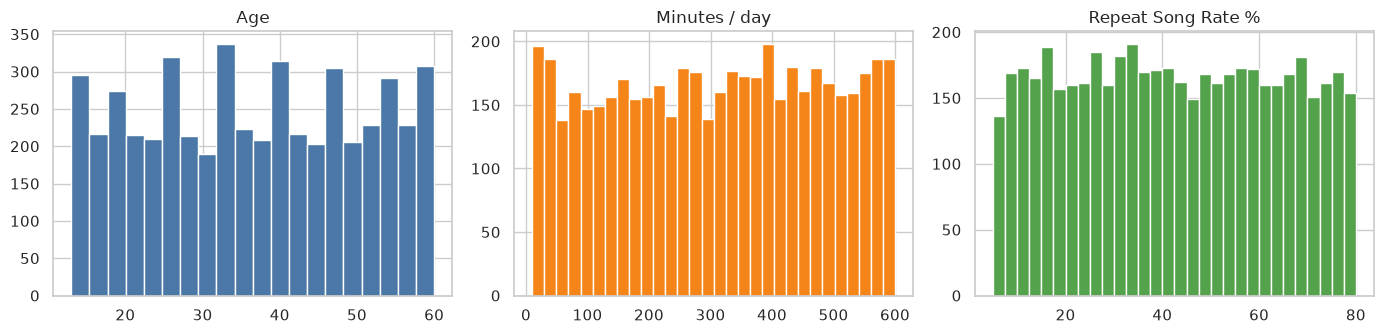

In [7]:
print("Age range:", music["Age"].min(), "→", music["Age"].max())
print("Minutes/day range:", music["Minutes Streamed Per Day"].min(), "→", music["Minutes Streamed Per Day"].max())
print("Discover Weekly % range:", music["Discover Weekly Engagement (%)"].min(), "→", music["Discover Weekly Engagement (%)"].max())
print("Repeat Song % range:", music["Repeat Song Rate (%)"].min(), "→", music["Repeat Song Rate (%)"].max())

# Histograms — visual check for weird spikes / impossible values
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
music["Age"].hist(ax=axes[0], bins=20, color="#4C78A8")
axes[0].set_title("Age")
music["Minutes Streamed Per Day"].hist(ax=axes[1], bins=30, color="#F58518")
axes[1].set_title("Minutes / day")
music["Repeat Song Rate (%)"].hist(ax=axes[2], bins=30, color="#54A24B")
axes[2].set_title("Repeat Song Rate %")
plt.tight_layout()
plt.show()


**Music verdict:** this file is already in good shape (comma separator, English decimals, no missing values). We still standardize column names later so merges are less painful.

---
## 2. Load the happiness dataset — see the problems first

If we open it the “normal” way, pandas assumes commas separate columns. This file uses **semicolons (`;`)** instead, so everything collapses into one column.


In [8]:
# WRONG load on purpose — so you see the symptom
broken = pd.read_csv(DATA / "world_happiness_data.csv")
print("Shape if we ignore the real delimiter:", broken.shape)
broken.head(2)


Shape if we ignore the real delimiter: (1502, 1)


,,,,,,Ranking;Country;Regional indicator;Happiness score;GDP per capita;Social support;Healthy life expectancy;Freedom to make life choices;Generosity;Perceptions of corruption;Year
1;Switzerland;Western Europe;7,58700;8,26132;0,96240;73;0,99379;0,37289;0,23941;2015
2;Iceland;Western Europe;7,56100;7,70416;1,00000;73;0,93884;0,54819;0,74371;2015


### Fix 1 — tell pandas the separator is `;`


In [9]:
happiness = pd.read_csv(DATA / "world_happiness_data.csv", sep=";")
print("Shape after sep=';':", happiness.shape)
happiness.head()


Shape after sep=';': (1502, 11)


,Ranking,Country,Regional indicator,Happiness score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Year
0,1,Switzerland,Western Europe,"7,58700","8,26132","0,96240",73,"0,99379","0,37289","0,23941",2015
1,2,Iceland,Western Europe,"7,56100","7,70416","1,00000",73,"0,93884","0,54819","0,74371",2015
2,3,Denmark,Western Europe,"7,52700","7,84114","0,97030",70,"0,96962","0,42894","0,12382",2015
3,4,Norway,Western Europe,"7,52200","8,63100","0,94917",71,"1,00000","0,43598","0,33860",2015
4,5,Canada,North America and ANZ,"7,42700","7,84595","0,94322",71,"0,94511","0,57560","0,40285",2015


### Fix 2 — European decimal commas → dots

Look at values like `7,58700`. In many European locales, **`,` means decimal point**. Python/pandas need `.` (e.g. `7.58700`).

If we leave commas, those columns stay as **text**, and you cannot compute means, train models, etc.


In [10]:
# Columns that should be numeric but currently look like text with commas
decimal_cols = [
    "Happiness score",
    "GDP per capita",
    "Social support",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption",
]

print("Before fixing — dtypes and a sample:")
print(happiness[decimal_cols].dtypes)
print(happiness[decimal_cols].head(2))


Before fixing — dtypes and a sample:
Happiness score                 str
GDP per capita                  str
Social support                  str
Freedom to make life choices    str
Generosity                      str
Perceptions of corruption       str
dtype: object
  Happiness score GDP per capita Social support Freedom to make life choices Generosity Perceptions of corruption
0         7,58700        8,26132        0,96240                      0,99379    0,37289                   0,23941
1         7,56100        7,70416        1,00000                      0,93884    0,54819                   0,74371


In [11]:
# Replace ',' with '.' then convert to float
for col in decimal_cols:
    happiness[col] = (
        happiness[col]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .astype(float)
    )

# These were already digit-looking; cast explicitly
happiness["Ranking"] = happiness["Ranking"].astype(int)
happiness["Healthy life expectancy"] = happiness["Healthy life expectancy"].astype(float)
happiness["Year"] = happiness["Year"].astype(int)

print("After fixing — dtypes:")
print(happiness.dtypes)
happiness.head(3)


After fixing — dtypes:
Ranking                           int64
Country                             str
Regional indicator                  str
Happiness score                 float64
GDP per capita                  float64
Social support                  float64
Healthy life expectancy         float64
Freedom to make life choices    float64
Generosity                      float64
Perceptions of corruption       float64
Year                              int64
dtype: object


,Ranking,Country,Regional indicator,Happiness score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Year
0,1,Switzerland,Western Europe,7.587,8.26132,0.9624,73.0,0.99379,0.37289,0.23941,2015
1,2,Iceland,Western Europe,7.561,7.70416,1.0000,73.0,0.93884,0.54819,0.74371,2015
2,3,Denmark,Western Europe,7.527,7.84114,0.9703,70.0,0.96962,0.42894,0.12382,2015


### Missing values (happiness)

Three rows have an empty **Regional indicator**. We can fill from other years of the same country (same country → same region).


In [12]:
print("Missing values:")
print(happiness.isna().sum())

missing_region = happiness[happiness["Regional indicator"].isna() | (happiness["Regional indicator"].astype(str).str.strip() == "")]
print("\nRows with missing region:")
display(missing_region[["Country", "Year", "Regional indicator", "Happiness score"]])


Missing values:
Ranking                         0
Country                         0
Regional indicator              3
Happiness score                 0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
Year                            0
dtype: int64

Rows with missing region:


,Country,Year,Regional indicator,Happiness score
394,Greece,2017,NaN,5.2270
673,Cyprus,2019,NaN,6.0458
743,Gambia,2019,NaN,4.5163


In [13]:
# Build a country → region map from rows that DO have a region
region_map = (
    happiness.loc[happiness["Regional indicator"].notna() & (happiness["Regional indicator"].astype(str).str.strip() != ""),
                  ["Country", "Regional indicator"]]
    .drop_duplicates(subset=["Country"])
    .set_index("Country")["Regional indicator"]
)

# Fill blanks using that map
blank = happiness["Regional indicator"].isna() | (happiness["Regional indicator"].astype(str).str.strip() == "")
happiness.loc[blank, "Regional indicator"] = happiness.loc[blank, "Country"].map(region_map)

print("Missing Regional indicator after fill:", happiness["Regional indicator"].isna().sum())
print("Filled countries:", missing_region["Country"].tolist())


Missing Regional indicator after fill: 0
Filled countries: ['Greece', 'Cyprus', 'Gambia']


### Duplicates

Same country + year twice would be a problem (two happiness scores for one key).


In [14]:
dupes = happiness.duplicated(subset=["Country", "Year"], keep=False)
print("Duplicate Country+Year rows:", dupes.sum())
if dupes.any():
    display(happiness.loc[dupes].sort_values(["Country", "Year"]))


Duplicate Country+Year rows: 0


In [15]:
# Numeric overview after cleaning types
happiness.describe()


,Ranking,Happiness score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Year
count,1502.000000,1502.000000,1502.000000,1502.000000,1502.000000,1502.000000,1502.000000,1502.000000,1502.000000
mean,76.035286,5.448857,6.107178,0.691842,66.670439,0.658935,0.320369,0.452764,2019.374834
std,43.865013,1.125638,2.499571,0.212647,7.671376,0.216441,0.172669,0.321786,2.856316
min,1.000000,1.721000,0.000000,0.000000,39.000000,0.000000,0.000000,0.000000,2015.000000
25%,38.000000,4.593425,4.375967,0.564507,62.000000,0.535942,0.196085,0.158585,2017.000000
50%,76.000000,5.469650,6.305600,0.738190,68.000000,0.690305,0.296375,0.345325,2019.000000
75%,114.000000,6.278450,8.047867,0.861528,72.000000,0.831792,0.430042,0.782560,2022.000000
max,158.000000,7.842100,10.000000,1.000000,85.000000,1.000000,1.000000,1.000000,2024.000000


---
## 3. Country names must match for a future merge

Music uses short names (`UK`, `USA`). Happiness uses official names (`United Kingdom`, `United States`).  
If we merge without fixing this, those users would **silently drop out** of the join.


In [16]:
music_countries = sorted(music["Country"].unique())
happy_countries = sorted(happiness["Country"].unique())

print("Music countries:", music_countries)
print("\nOverlap already:", sorted(set(music_countries) & set(happy_countries)))
print("In music but NOT in happiness:", sorted(set(music_countries) - set(happy_countries)))


Music countries: ['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'India', 'Japan', 'South Korea', 'UK', 'USA']

Overlap already: ['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'India', 'Japan', 'South Korea']
In music but NOT in happiness: ['UK', 'USA']


In [17]:
# Explicit rename map — only change what must match
country_aliases = {
    "UK": "United Kingdom",
    "USA": "United States",
}

music["Country"] = music["Country"].replace(country_aliases)

print("After rename — music countries:", sorted(music["Country"].unique()))
print("Still missing from happiness?:", sorted(set(music["Country"].unique()) - set(happiness["Country"].unique())))


After rename — music countries:

 ['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'India', 'Japan', 'South Korea', 'United Kingdom', 'United States']
Still missing from happiness?: []


---
## 4. Optional polish — cleaner column names

Spaces and `%` in names work, but snake_case is easier in code (`df.happiness_score` vs `df["Happiness score"]`).


In [18]:
def to_snake(name: str) -> str:
    return (
        name.strip()
        .lower()
        .replace("%", "pct")
        .replace("(", "")
        .replace(")", "")
        .replace("/", "_")
        .replace(" ", "_")
        .replace("__", "_")
    )

music = music.rename(columns={c: to_snake(c) for c in music.columns})
happiness = happiness.rename(columns={c: to_snake(c) for c in happiness.columns})

print("Music columns:", list(music.columns))
print("Happiness columns:", list(happiness.columns))


Music columns: ['user_id', 'age', 'country', 'streaming_platform', 'top_genre', 'minutes_streamed_per_day', 'number_of_songs_liked', 'most_played_artist', 'subscription_type', 'listening_time_morning_afternoon_night', 'discover_weekly_engagement_pct', 'repeat_song_rate_pct']
Happiness columns: ['ranking', 'country', 'regional_indicator', 'happiness_score', 'gdp_per_capita', 'social_support', 'healthy_life_expectancy', 'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption', 'year']


---
## 5. Save cleaned datasets

We write new files so the originals stay untouched (good habit: never overwrite raw data).


In [19]:
out_dir = DATA / "cleaned"
out_dir.mkdir(exist_ok=True)

music_path = out_dir / "music_clean.csv"
happ_path = out_dir / "happiness_clean.csv"

music.to_csv(music_path, index=False)
happiness.to_csv(happ_path, index=False)

print("Saved:", music_path.resolve())
print("Saved:", happ_path.resolve())
print("\nMusic shape:", music.shape, "| Happiness shape:", happiness.shape)


Saved: /home/wissemsirat/Documents/Projects/musicml/cleaned/music_clean.csv
Saved: /home/wissemsirat/Documents/Projects/musicml/cleaned/happiness_clean.csv

Music shape: (5000, 12) | Happiness shape: (1502, 11)


---
## 6. Quick preview of the merge (next step, not modeling yet)

One happiness score per country per year. Music has no year, so a common approach is:
use the **latest year** of happiness per country, then join on `country`.


In [20]:
latest_year = happiness["year"].max()
happ_latest = happiness[happiness["year"] == latest_year].copy()
print(f"Using happiness year {latest_year}: {len(happ_latest)} countries")

merged = music.merge(happ_latest, on="country", how="left", suffixes=("", "_happ"))

print("Merged shape:", merged.shape)
print("Users with no happiness match:", merged["happiness_score"].isna().sum())
merged[["user_id", "country", "age", "top_genre", "happiness_score", "gdp_per_capita"]].head(10)


Using happiness year 2024: 140 countries


Merged shape: (5000, 22)
Users with no happiness match: 0


,user_id,country,age,top_genre,happiness_score,gdp_per_capita
0,U1000,Japan,34,Reggae,6.0598,8.34247
1,U1001,Germany,24,Country,6.7185,8.74242
2,U1002,Germany,49,Pop,6.7185,8.74242
3,U1003,Australia,55,Reggae,7.0569,8.66266
4,U1004,Germany,13,Reggae,6.7185,8.74242
5,U1005,South Korea,25,EDM,6.0579,8.47919
6,U1006,Australia,49,Country,7.0569,8.66266
7,U1007,United Kingdom,32,Classical,6.7490,8.51296
8,U1008,Germany,25,Metal,6.7185,8.74242
9,U1009,Brazil,37,Reggae,6.2720,6.67841


---
## Checklist — what cleaning did for us

1. **Music** — verified types, no missing values, no duplicate users; renamed `UK`/`USA` for joining.
2. **Happiness** — fixed `;` separator, fixed decimal commas → floats, filled 3 missing regions, checked Country+Year uniqueness.
3. **Saved** clean CSVs under `cleaned/`.
4. **Previewed** a left-join on `country` using the latest happiness year.

### Typical next steps (when you're ready)
1. **EDA** — correlations, groupbys (genre vs happiness, platform vs minutes…).
2. **Feature prep** — encode categories, scale numbers, choose a target (e.g. predict `subscription_type` or `minutes_streamed_per_day`).
3. **Train/test split + model** with scikit-learn.

Re-run this notebook any time with: activate `.venv`, then `jupyter notebook` (or open the `.ipynb` in Cursor/VS Code and pick the `.venv` kernel).
